In [1]:
#!/usr/bin/env python3
%load_ext autoreload
%autoreload 2
# Standard library
# import os


import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import itertools
import json
from scipy.integrate import cumulative_trapezoid
import numpy.typing as npt
import matplotlib.lines as mlines
import datetime as dt
import cftime as ct

from utils import a
from wcd_style import style, set_size, LABELS, TEXTWIDTH, COLUMNWIDTH

IntArray1D_T = npt.NDArray[np.int_]




In [2]:
# climatological SST, h derived from it

from utils import const_cp
from metpy.calc import saturation_vapor_pressure
from metpy.units import units
icL = 2.5008e6

rawpath = "/net/ch4/atmcirc/schemms/icon/ENS_n1_APE_266_JABW_R02B05_G_qobs/year1"
rawpath_4K = "/net/ch4/atmcirc/schemms/icon/ENS_n1_APE_266_JABW_R02B05_G_qobs_4K/year1"

iconpath = "/net/helium/atmosdyn/jzibell/icon/ens"

member = "ENS_n1_APE_266_JABW_R02B05_G_qobs"
member_4K = "ENS_n1_APE_266_JABW_R02B05_G_qobs_4K"

R_d = 287.05
R_v = 461.51

def specific_humidity(SST, RH=100):
    p = 101325 * units.Pa
    
    e_s = saturation_vapor_pressure(SST)
    
    e = RH / 100 * e_s
    
    return e * R_d / ( R_v * (p - e) )
    


In [3]:


analysis_ystart = 2000
analysis_mstart = 4
# analysis_yend = 2000 
# analysis_mend = 6
analysis_yend = 2009 
analysis_mend = 10

analysis_start = ct.Datetime360Day(analysis_ystart, analysis_mstart, 1, 3, 0, 0)
analysis_end = ct.Datetime360Day(analysis_yend, analysis_mend, 30, 21, 0, 0)

percentile_ystart = 2000
percentile_mstart = 4
percentile_yend = 2009
percentile_mend = 10

percentile_start = ct.Datetime360Day(percentile_ystart, percentile_mstart, 1, 3, 0, 0)
percentile_end = ct.Datetime360Day(percentile_yend, percentile_mend, 30, 21, 0, 0)


ct_monthstamps = [analysis_start]
iterator = 0
while ct_monthstamps[-1] <= analysis_end - dt.timedelta(days=30):
    ct_monthstamps.append(ct_monthstamps[-1] + dt.timedelta(days=30))
    
    iterator += 1
    if iterator > 3000:
        raise Exception("while not terminating")


analysis_period_filestring_icon = f"{analysis_ystart}-{analysis_mstart}_{analysis_yend}-{analysis_mend}"


In [10]:
g = 9.81
lat = rad_ctrl.lat

## direct AHT

In [5]:
# load the MSE transports calculated dynamically
def load_aht(timestamps, member:str, scale=1e15):
    
    msepath = "/net/helium/atmosdyn/jzibell/icon/ens/temp/MSE"

    # member = "ENS_n1_APE_266_JABW_R02B05_G_qobs"
    # member_4K = "ENS_n1_APE_266_JABW_R02B05_G_qobs_4K"




    TE = xr.open_mfdataset(
        [
            f"{msepath}/VIDECOMP_TE_{member}_3D_splitmon{stamp.year}_{stamp.month:02d}_fullfield_icL_monmean_wght_zonmean_PS_0.nc"
            for stamp in timestamps
        ],concat_dim="time", combine="nested",
    )
    
    lat = TE.lat
    
    SE = xr.open_mfdataset(
        [
            f"{msepath}/VIDECOMP_SE_{member}_3D_splitmon{stamp.year}_{stamp.month:02d}_fullfield_icL_monmean_wght_zonmean_PS_0.nc"
            for stamp in timestamps
        ],concat_dim="time", combine="nested",
    )
    
    MM = xr.open_mfdataset(
        [
            f"{msepath}/VIDECOMP_MM_{member}_3D_splitmon{stamp.year}_{stamp.month:02d}_fullfield_icL_monmean_bar_vert_anom_PS_0.nc"
            for stamp in timestamps
        ],concat_dim="time", combine="nested",
    )
    
    total = (TE["VIcpT_TE"] + TE["VILq_TE"] + TE["VIZ_TE"] +
            SE["VIcpT_SE"] + SE["VILq_SE"] + SE["VIZ_SE"] +
            MM["VIcpT_MM_vanom"] + MM["VILq_MM_vanom"] + MM["VIZ_MM_vanom"])
    
    return total.mean("time") * np.cos(np.deg2rad(lat)) * 2 * np.pi * a / scale * 100 / g# hPa


## Radiatively determined transport

In [11]:
radpath = "/net/helium/atmosdyn/jzibell/icon/ens/temp/MSE"

eia_stamps = [
    ct.Datetime360Day(stamp.year, stamp.month, 16, 0, 0, 0) for stamp in ct_monthstamps
]
rad_ctrl = (
    xr.open_dataset(f"{radpath}/EIA_{member}_monmean_meanremoved.nc")
    .sel(time=eia_stamps)
    .mean(("lon", "time"))
)

eia_ctrl = (
    rad_ctrl["sob_t"]
    - rad_ctrl["sob_s"]
    + rad_ctrl["thb_t"]
    - rad_ctrl["thb_s"]
    - rad_ctrl["shfl_s"]
    - rad_ctrl["lhfl_s"]
)

rad_4K = (
    xr.open_dataset(f"{radpath}/EIA_{member_4K}_monmean_meanremoved.nc")
    .sel(time=eia_stamps)
    .mean(("lon", "time"))
)

eia_4K = (
    rad_4K["sob_t"]
    - rad_4K["sob_s"]
    + rad_4K["thb_t"]
    - rad_4K["thb_s"]
    - rad_4K["shfl_s"]
    - rad_4K["lhfl_s"]
)


rad_ctrl_abs = (
    xr.open_dataset(f"{radpath}/EIA_{member}_monmean.nc")
    .sel(time=eia_stamps)
    .mean(("lon", "time"))
)

eia_ctrl_abs = (
    rad_ctrl_abs["sob_t"]
    - rad_ctrl_abs["sob_s"]
    + rad_ctrl_abs["thb_t"]
    - rad_ctrl_abs["thb_s"]
    - rad_ctrl_abs["shfl_s"]
    - rad_ctrl_abs["lhfl_s"]
)

rad_4K_abs = (
    xr.open_dataset(f"{radpath}/EIA_{member_4K}_monmean.nc")
    .sel(time=eia_stamps)
    .mean(("lon", "time"))
)

eia_4K_abs = (
    rad_4K_abs["sob_t"]
    - rad_4K_abs["sob_s"]
    + rad_4K_abs["thb_t"]
    - rad_4K_abs["thb_s"]
    - rad_4K_abs["shfl_s"]
    - rad_4K_abs["lhfl_s"]
)

def flux_from_radiation(eia, scale=1e15):
    # eia = (
    #     data["sob_t"]
    #     - data["sob_s"]
    #     + data["thb_t"]
    #     - data["thb_s"]
    #     - data["shfl_s"]
    #     - data["lhfl_s"]
    # )
    
    lat_rad = np.deg2rad(lat.values)
    
    # start from south pole
    flux_SH = (
        1 / scale
        * 2
        * np.pi
        * a**2
        * cumulative_trapezoid(np.cos(lat_rad) * eia.values, x=lat_rad, initial=0.0)
    )
    
    # start from north pole
    flux_NH = -(
        1 / scale
        * 2
        * np.pi
        * a**2
        * cumulative_trapezoid(np.cos(lat_rad) * eia.values[::-1], x=lat_rad, initial=0.0)
    )[::-1]

    return flux_SH, flux_NH


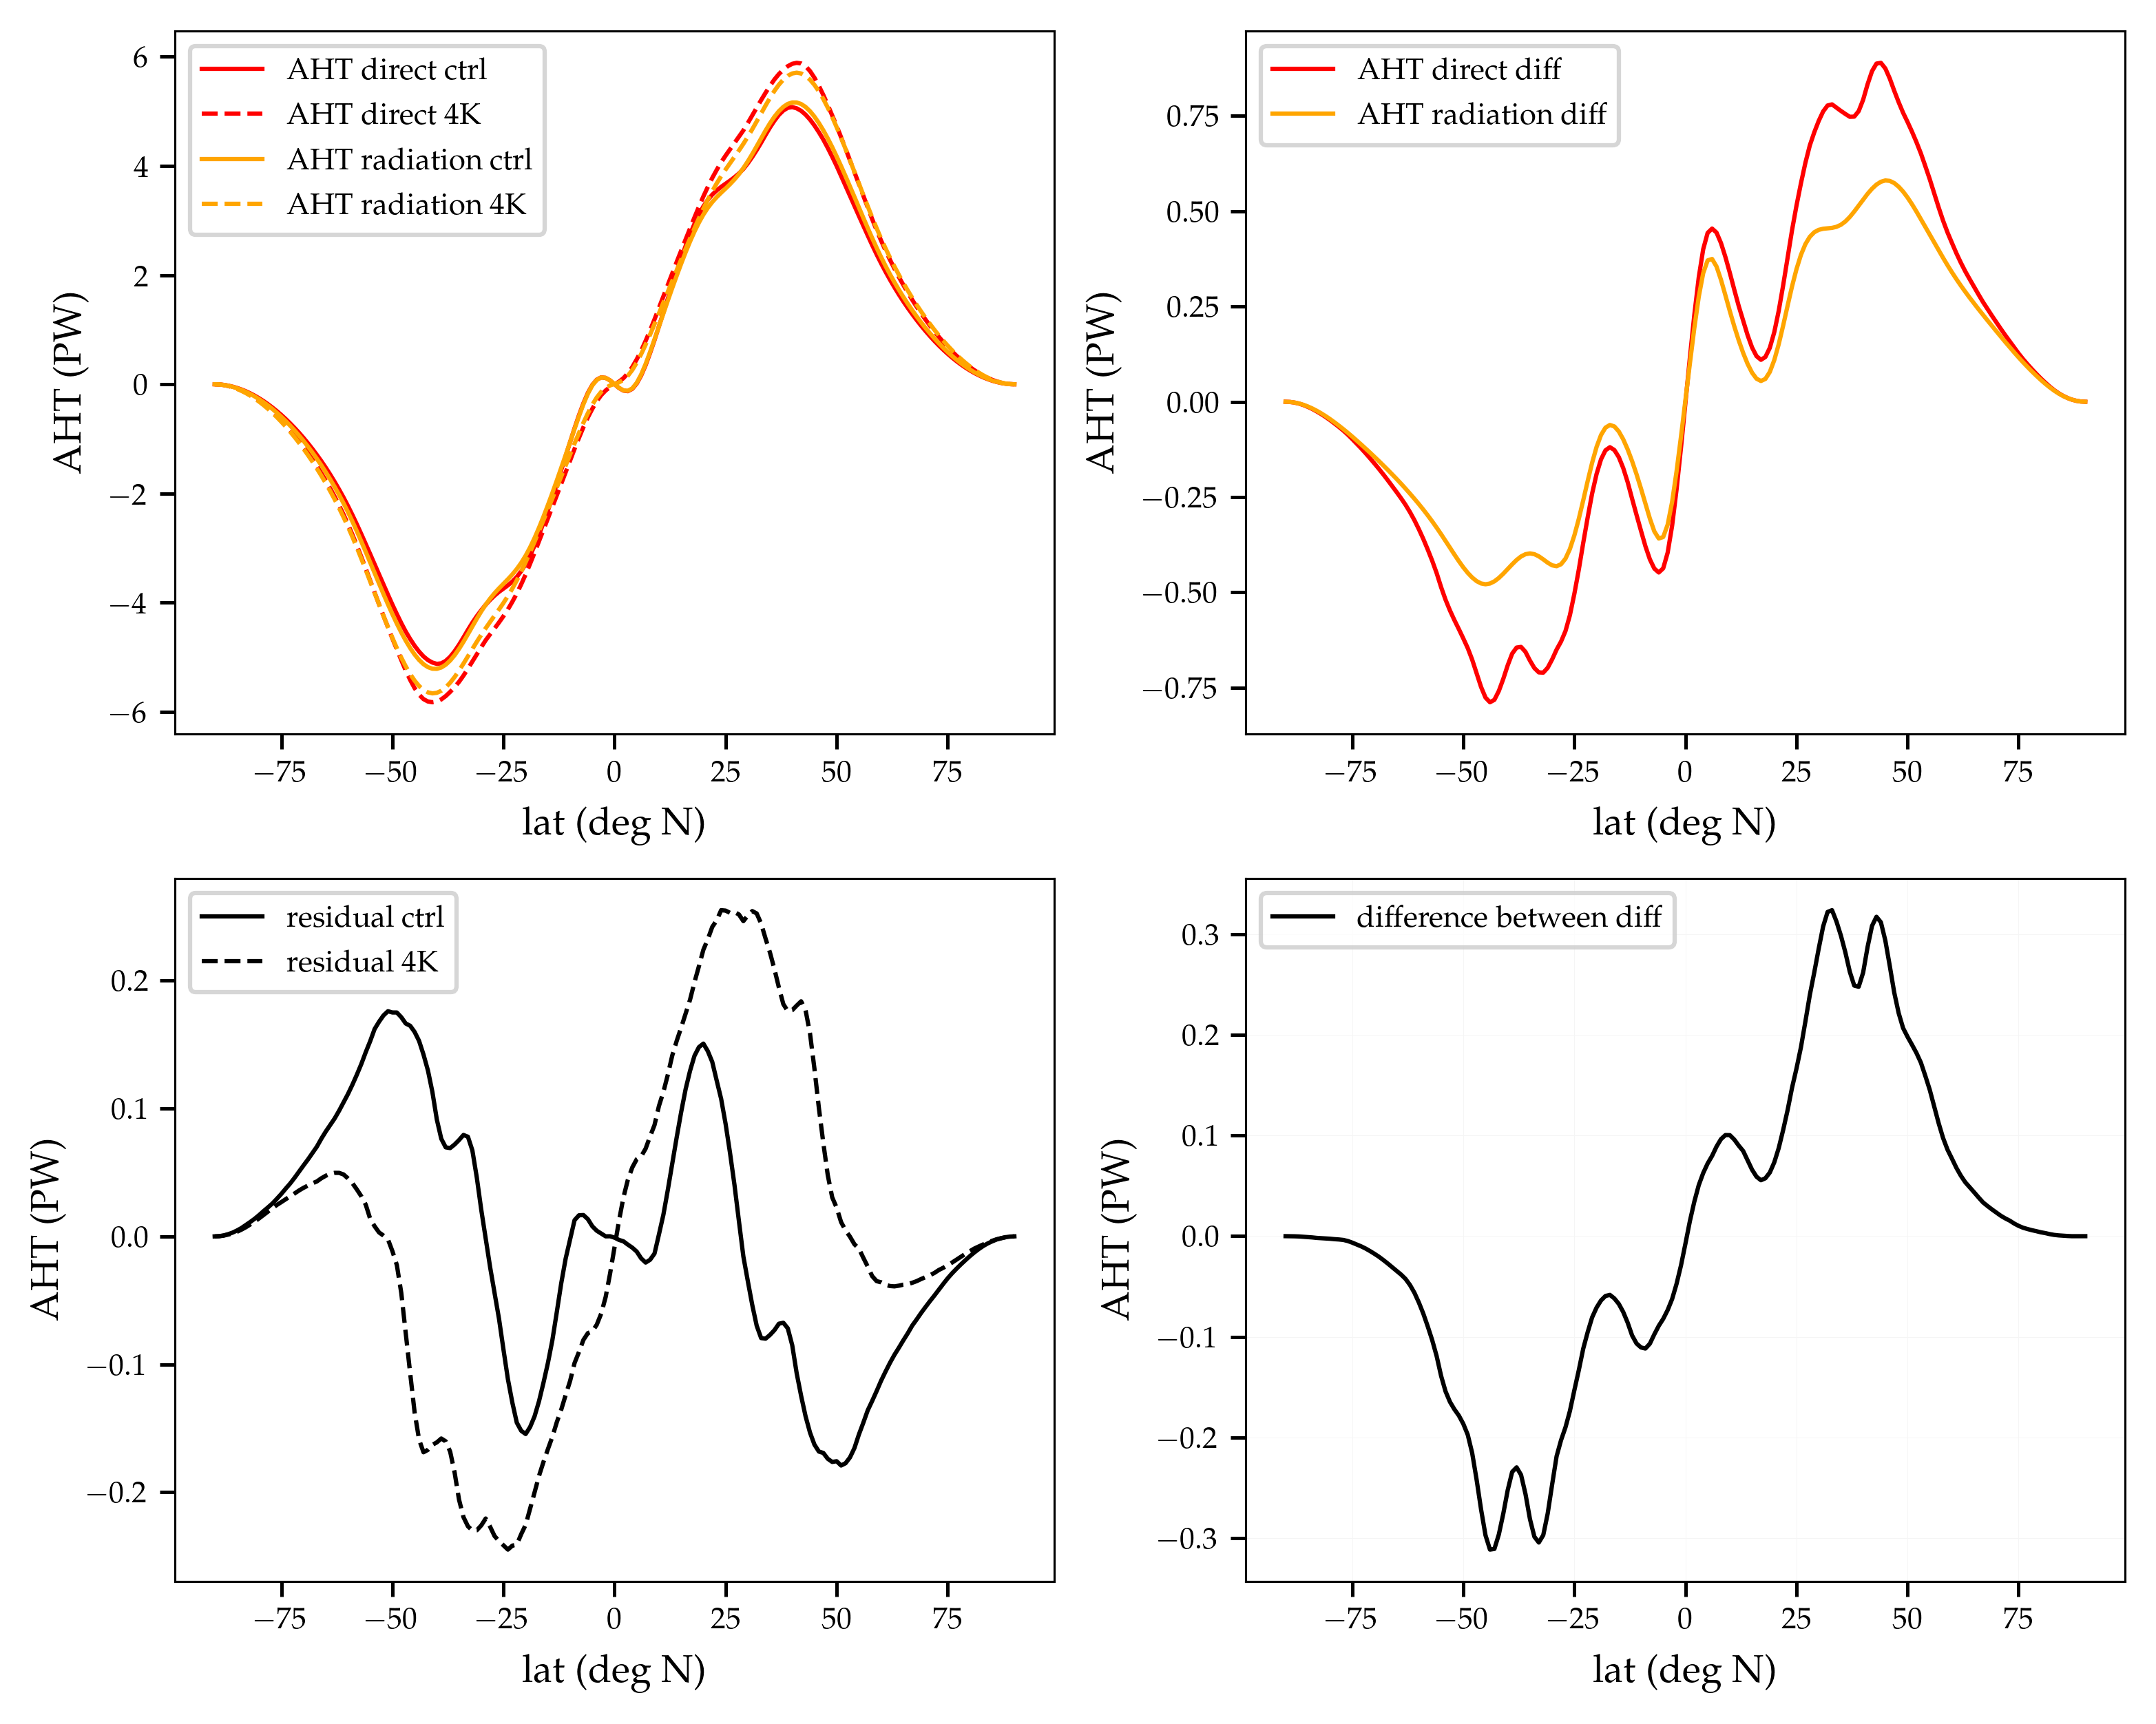

In [12]:
style()
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=set_size(width=TEXTWIDTH, ratio= 0.8))

axs = axes.flatten()
figpath = "/home/jzibell/phd/icon/MSE"

ax = axs[0]


ax.plot(lat, load_aht(ct_monthstamps, member=member), color='r', label='AHT direct ctrl') #, alpha=0.5)
ax.plot(lat, load_aht(ct_monthstamps, member=member_4K), color='r', label='AHT direct 4K', linestyle='--') #, alpha=0.5)
ax.plot(lat,
        flux_from_radiation(eia_ctrl)[0],
        color='orange', label='AHT radiation ctrl') #, alpha=0.5)

ax.plot(lat,
        flux_from_radiation(eia_4K)[0],
        color='orange', label='AHT radiation 4K', linestyle='--') #, alpha=0.5)

ax.legend()
ax = axs[1]


ax.plot(lat, 
        load_aht(ct_monthstamps, member=member_4K) - load_aht(ct_monthstamps, member=member),
        color='r', label='AHT direct diff') #, alpha=0.5)

ax.plot(lat,
        flux_from_radiation(eia_4K)[0] - flux_from_radiation(eia_ctrl)[0],
        color='orange', label='AHT radiation diff') #, alpha=0.5)


ax.legend()


ax = axs[2]



ax.plot(lat, load_aht(ct_monthstamps, member=member).squeeze() - flux_from_radiation(eia_ctrl)[0], color='k', label='residual ctrl') #, alpha=0.5)
ax.plot(lat, load_aht(ct_monthstamps, member=member_4K).squeeze() - flux_from_radiation(eia_4K)[0], color='k', label='residual 4K', linestyle='--') #, alpha=0.5)

ax.legend()

ax = axs[3]

ax.plot(lat, 
        load_aht(ct_monthstamps, member=member_4K).squeeze() - load_aht(ct_monthstamps, member=member).squeeze() - (flux_from_radiation(eia_4K)[0] - flux_from_radiation(eia_ctrl)[0]),
        color='k', label='difference between diff') #, alpha=0.5)



ax.legend()



for ax_i in axs:
    ax_i.set(
        ylabel='AHT (PW)',
        xlabel='lat (deg N)'
    )
    ax.grid(True)



fig.tight_layout()
fig.savefig(f"{figpath}/icon_zonmean_aht_closure_{member}_{analysis_period_filestring_icon}.png", dpi=400)
plt.show()
plt.close()

In [13]:
def f_cos_lat_weighted_mean_zonal_arr(arr,lats) -> float:
    """
    returns weighted aereal mean
    """
    if np.max(lats) > 90:
        lats_loc = lats - 90
    else:
        lats_loc = lats
    weights = np.cos(np.deg2rad(lats_loc))
    
    return np.dot(weights, arr) / np.sum(weights)


toa_ctrl = (
    rad_ctrl["sob_t"]
    + rad_ctrl["thb_t"]
)


toa_4K = (
    rad_4K["sob_t"]
    + rad_4K["thb_t"]
)



toa_ctrl_abs = (
    rad_ctrl_abs["sob_t"]
    + rad_ctrl_abs["thb_t"]
)


toa_4K_abs = (
    rad_4K_abs["sob_t"]
    + rad_4K_abs["thb_t"]
)



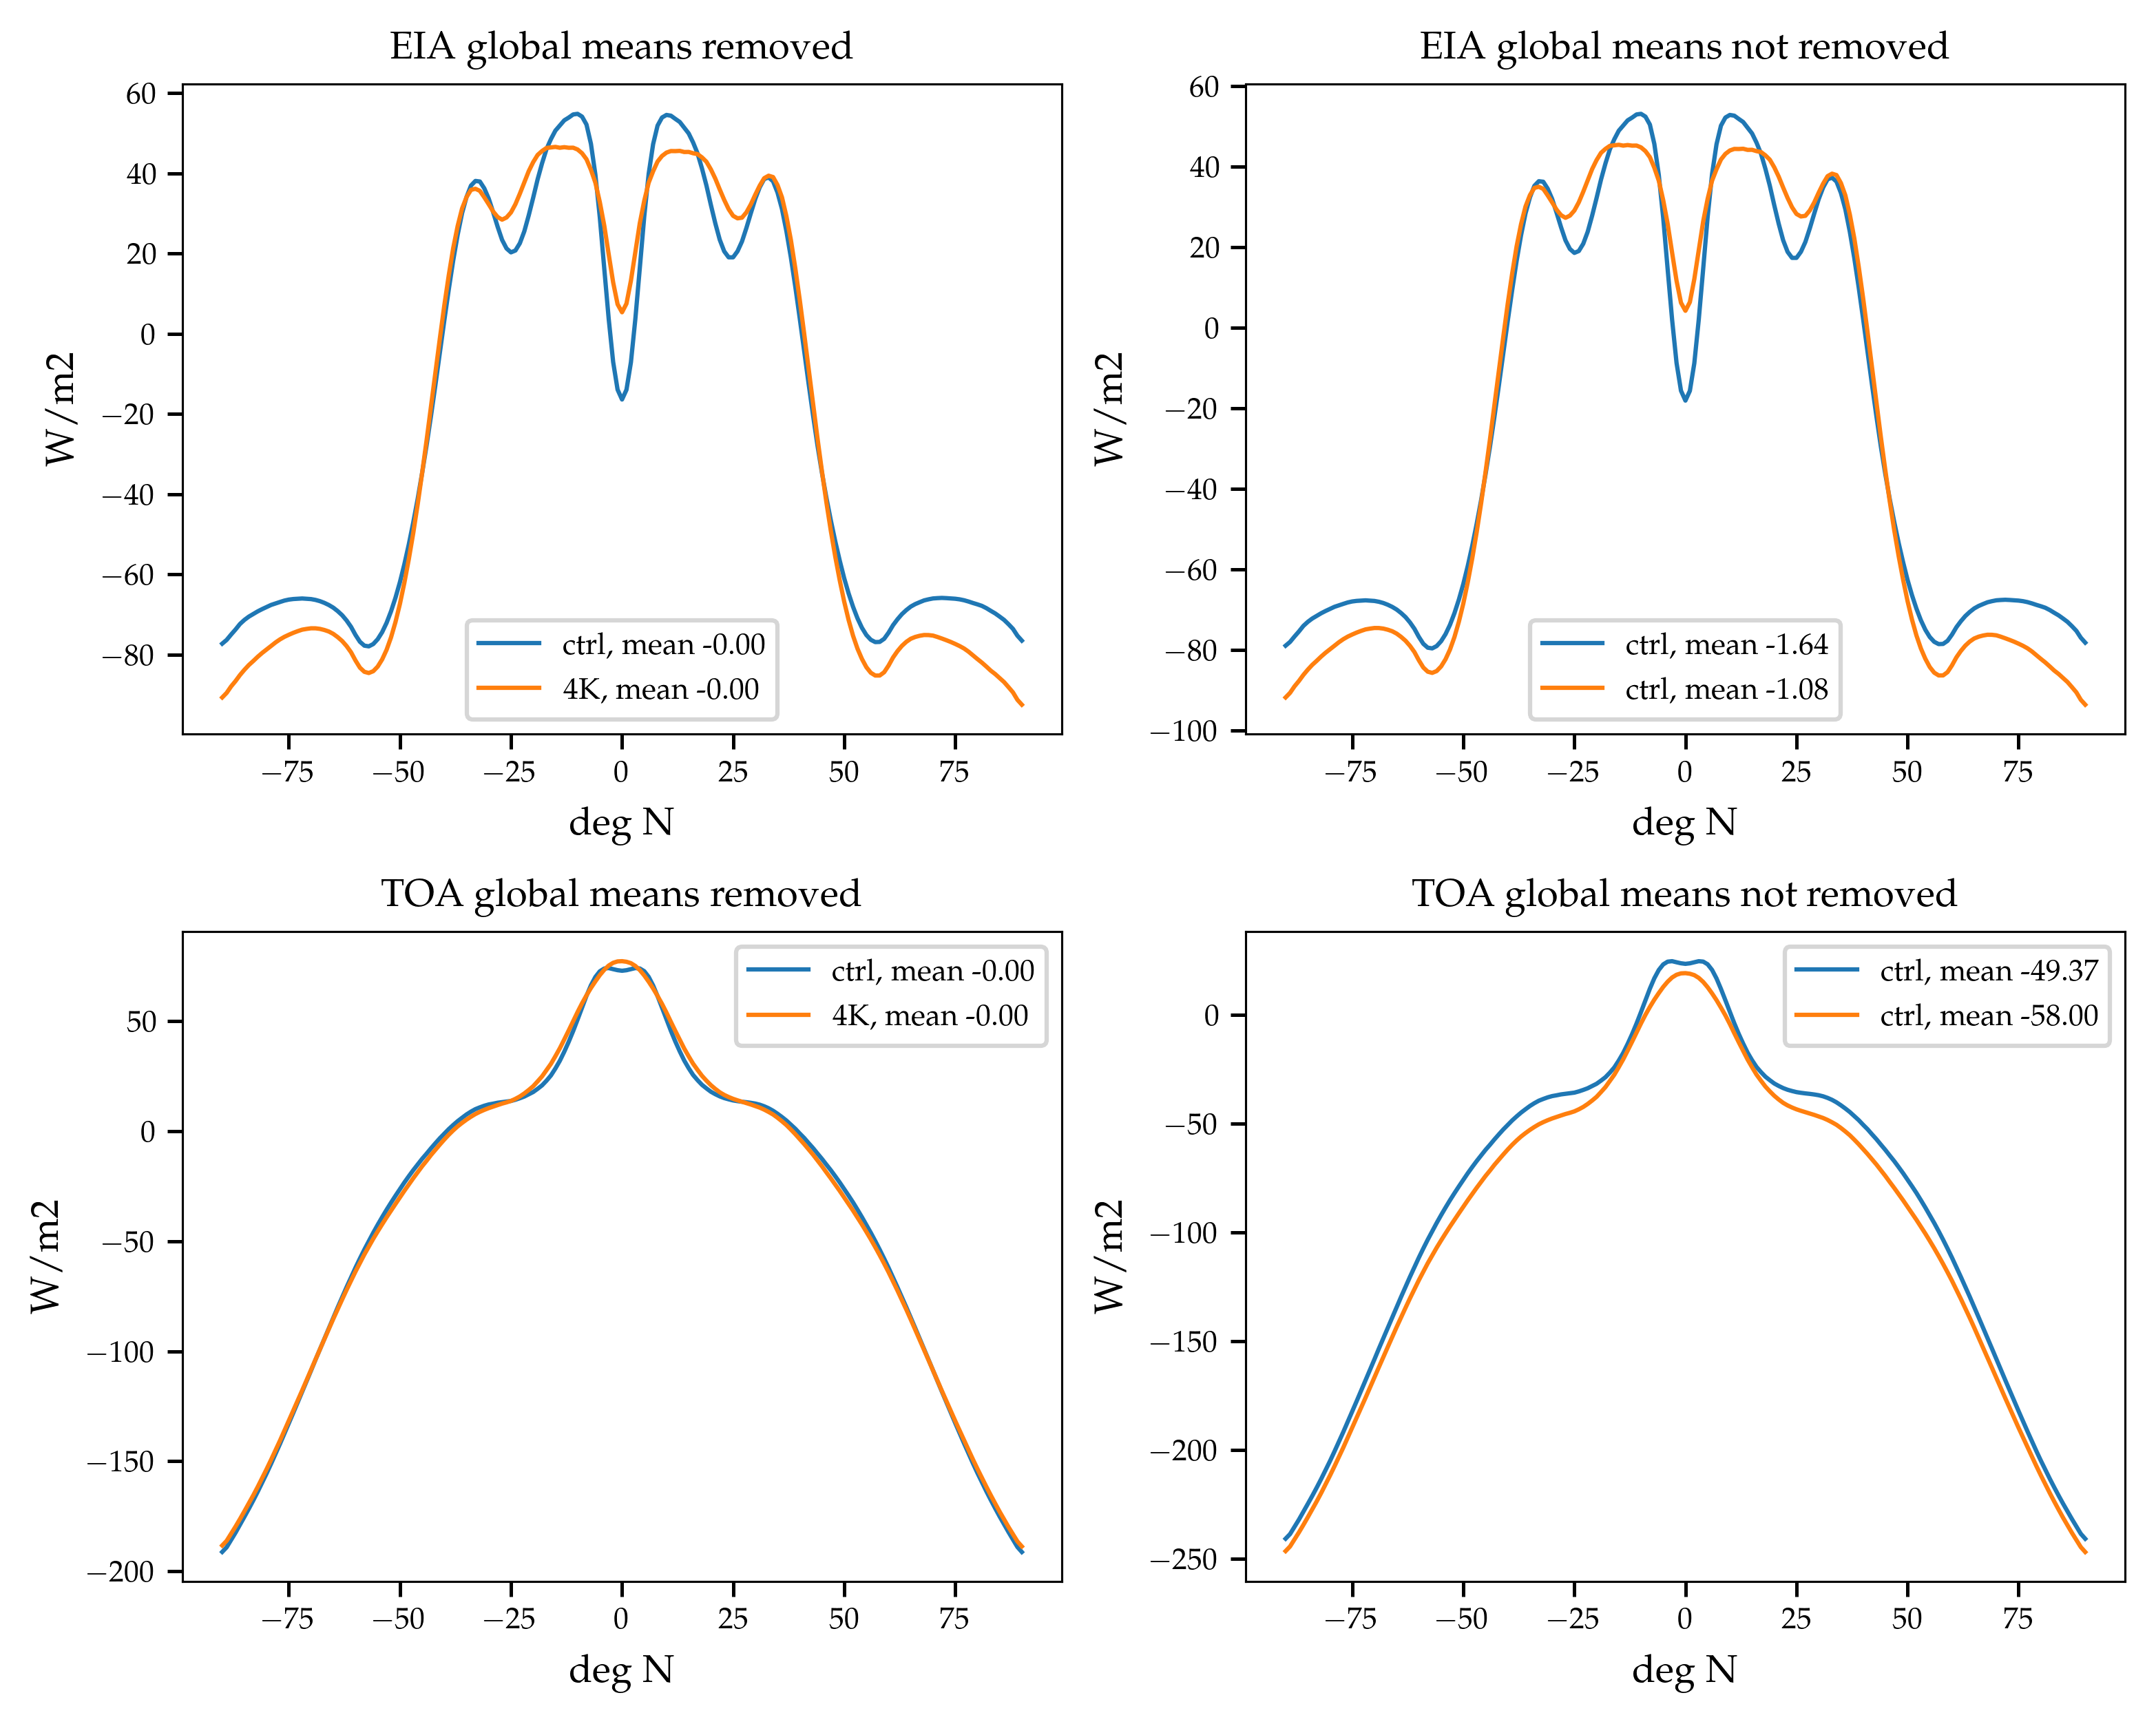

In [14]:

style()
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=set_size(width=TEXTWIDTH, ratio= 0.8))

axs = axes.flatten()
figpath = "/home/jzibell/phd/icon/MSE"

ax = axs[0]

ax.set(
    title="EIA global means removed"
)
ax.plot(lat, eia_ctrl, label=f'ctrl, mean {f_cos_lat_weighted_mean_zonal_arr(eia_ctrl, lats=lat):.02f}')
ax.plot(lat, eia_4K, label=f'4K, mean {f_cos_lat_weighted_mean_zonal_arr(eia_4K, lats=lat):.02f}')


ax = axs[1]


ax.set(
    title="EIA global means not removed"
)
ax.plot(lat, eia_ctrl_abs, label=f'ctrl, mean {f_cos_lat_weighted_mean_zonal_arr(eia_ctrl_abs, lats=lat):.02f}')
ax.plot(lat, eia_4K_abs, label=f'ctrl, mean {f_cos_lat_weighted_mean_zonal_arr(eia_4K_abs, lats=lat):.02f}')


# TOA
ax = axs[2]

ax.set(
    title="TOA global means removed"
)
ax.plot(lat, toa_ctrl, label=f'ctrl, mean {f_cos_lat_weighted_mean_zonal_arr(toa_ctrl, lats=lat):.02f}')
ax.plot(lat, toa_4K, label=f'4K, mean {f_cos_lat_weighted_mean_zonal_arr(toa_4K, lats=lat):.02f}')


ax = axs[3]


ax.set(
    title="TOA global means not removed"
)
ax.plot(lat, toa_ctrl_abs, label=f'ctrl, mean {f_cos_lat_weighted_mean_zonal_arr(toa_ctrl_abs, lats=lat):.02f}')
ax.plot(lat, toa_4K_abs, label=f'ctrl, mean {f_cos_lat_weighted_mean_zonal_arr(toa_4K_abs, lats=lat):.02f}')




for ax in axs:
    ax.set(
        ylabel='W/m2',
        xlabel='deg N'
    )
    ax.legend()


fig.tight_layout()
fig.savefig(f"{figpath}/icon_zonmean_eia_toa_{member}_{analysis_period_filestring_icon}.png", dpi=400)
plt.show()
plt.close()

